In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

orders = pd.read_csv("orders.csv")
riders = pd.read_csv("riders.csv")
routes = pd.read_csv("routes.csv")
weather = pd.read_csv("weather.csv")
delivery = pd.read_csv("delivery.csv")

print("All five datasets loaded successfully!")


All five datasets loaded successfully!


In [3]:

datasets = {
    "Orders": orders,
    "Riders": riders,
    "Routes": routes,
    "Weather": weather,
    "Delivery": delivery
}

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]} rows, {df.shape[1]} columns")



Orders: 505 rows, 5 columns
Riders: 40 rows, 4 columns
Routes: 500 rows, 4 columns
Weather: 500 rows, 4 columns
Delivery: 500 rows, 5 columns


In [4]:

print("ORDERS DATA")
display(orders.head())

print("RIDERS DATA")
display(riders.head())

print("ROUTES DATA")
display(routes.head())

print("WEATHER DATA")
display(weather.head())

print("DELIVERY DATA")
display(delivery.head())


ORDERS DATA


,order_id,order_time,restaurant,customer_zone,order_value
0,QB10001,2026-09-19 13:35:00,Green Bowl,South,204.65
1,QB10002,2026-09-02 23:04:00,Pizza Point,North,247.17
2,QB10003,2026-09-13 06:34:00,Curry Corner,West,847.94
3,QB10004,2026-09-02 09:52:00,Tandoori Trail,Ctr,522.41
4,QB10005,2026-09-20 19:45:00,Pizza Point,Airport,480.23


RIDERS DATA


,rider_id,rider_name,experience_months,shift
0,R001,Rider 01,41,Afternoon
1,R002,Rider 02,2,Evening
2,R003,Rider 03,28,Evening
3,R004,Rider 04,50,Morning
4,R005,Rider 05,2,Afternoon


ROUTES DATA


,order_id,distance_km,traffic_level,zone
0,QB10001,7.45,High,South
1,QB10002,2.16,Low,North
2,QB10003,8.50,Low,West
3,QB10004,5.50,High,Central
4,QB10005,2.09,Medium,Airport


WEATHER DATA


,order_id,rain_level,temperature_c,visibility_km
0,QB10001,Moderate,25.8,11.2
1,QB10002,NaN,30.3,8.0
2,QB10003,NaN,34.2,7.8
3,QB10004,NaN,37.8,9.3
4,QB10005,NaN,32.7,10.1


DELIVERY DATA


,order_id,rider_id,pickup_time,delivered_time,status
0,QB10001,R017,2026-09-19 13:58:10,2026-09-19 15:14:10,Delivered
1,QB10002,R022,2026-09-02 23:28:02,2026-09-03 00:03:32,Delivered
2,QB10003,R023,2026-09-13 06:55:33,2026-09-13 07:54:10,Cancelled
3,QB10004,R030,2026-09-02 10:18:32,2026-09-02 11:13:04,Cancelled
4,QB10005,R027,2026-09-20 19:51:58,2026-09-20 20:24:51,Delivered


In [5]:

for name, df in datasets.items():
    print(f"\n{'=' * 15} {name.upper()} {'=' * 15}")
    df.info()



=============== ORDERS ===============
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 505 entries, 0 to 504
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   order_id       505 non-null    object 
 1   order_time     498 non-null    object 
 2   restaurant     505 non-null    object 
 3   customer_zone  505 non-null    object 
 4   order_value    505 non-null    float64
dtypes: float64(1), object(4)
memory usage: 19.9+ KB

=============== RIDERS ===============
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   rider_id           40 non-null     object
 1   rider_name         40 non-null     object
 2   experience_months  40 non-null     int64 
 3   shift              40 non-null     object
dtypes: int64(1), object(3)
memory usage: 1.4+ KB

=============== ROUT

In [6]:

for name, df in datasets.items():
    print(f"\n{name.upper()}")
    print(df.isnull().sum())



ORDERS
order_id         0
order_time       7
restaurant       0
customer_zone    0
order_value      0
dtype: int64

RIDERS
rider_id             0
rider_name           0
experience_months    0
shift                0
dtype: int64

ROUTES
order_id         0
distance_km      0
traffic_level    0
zone             0
dtype: int64

WEATHER
order_id           0
rain_level       283
temperature_c     22
visibility_km     25
dtype: int64

DELIVERY
order_id          0
rider_id          0
pickup_time       8
delivered_time    9
status            0
dtype: int64


In [7]:

# 1. Check duplicate order IDs
print("Duplicate order IDs:", orders["order_id"].duplicated().sum())

# 2. Check missing values across all datasets
for name, df in datasets.items():
    print(f"\n{name} - Missing values:")
    print(df.isnull().sum()[df.isnull().sum() > 0])

# 3. Check inconsistent zone names
print("\nCustomer zones:")
print(sorted(orders["customer_zone"].dropna().astype(str).unique()))

print("\nRoute zones:")
print(sorted(routes["zone"].dropna().astype(str).unique()))

# 4. Convert timestamps to datetime
for col in ["order_time"]:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

for col in ["pickup_time", "delivered_time"]:
    delivery[col] = pd.to_datetime(delivery[col], errors="coerce")

# 5. Identify negative delivery durations
delivery["delivery_duration_min"] = (
    delivery["delivered_time"] - delivery["pickup_time"]
).dt.total_seconds() / 60

print("\nNegative delivery durations:",
      (delivery["delivery_duration_min"] < 0).sum())


Duplicate order IDs: 5

Orders - Missing values:
order_time    7
dtype: int64

Riders - Missing values:
Series([], dtype: int64)

Routes - Missing values:
Series([], dtype: int64)

Weather - Missing values:
rain_level       283
temperature_c     22
visibility_km     25
dtype: int64

Delivery - Missing values:
pickup_time       8
delivered_time    9
dtype: int64

Customer zones:
[' CENTRAL ', ' EAST ', ' NORTH ', ' SOUTH ', ' WEST ', 'Airport', 'Central', 'Ctr', 'East', 'N', 'North', 'OLD TOWN ', 'Old Town', 'Oldtown', 'South', 'TECH PARK ', 'Tech Park', 'Techpark', 'West', 'airport', 'central', 'east', 'north', 'old town', 'south', 'tech park']

Route zones:
[' CENTRAL ', ' EAST ', ' SOUTH ', ' WEST ', 'Airport', 'Central', 'Ctr', 'E', 'East', 'N', 'North', 'OLD TOWN ', 'Old Town', 'Oldtown', 'S', 'South', 'TECH PARK ', 'Tech Park', 'Techpark', 'W', 'West', 'airport', 'central', 'east', 'north', 'south', 'tech park', 'west']

Negative delivery durations: 5


In [8]:

# 1. Remove duplicate order records
orders = orders.drop_duplicates(subset="order_id", keep="first").copy()

# 2. Standardize zone names
zone_mapping = {
    "central": "Central", "ctr": "Central",
    "north": "North", "n": "North",
    "south": "South", "s": "South",
    "east": "East", "e": "East",
    "west": "West", "w": "West",
    "airport": "Airport", "air port": "Airport",
    "tech park": "Tech Park", "techpark": "Tech Park",
    "old town": "Old Town", "oldtown": "Old Town"
}

def clean_zone(series):
    return series.astype("string").str.strip().str.lower().map(zone_mapping)

orders["customer_zone"] = clean_zone(orders["customer_zone"])
routes["zone"] = clean_zone(routes["zone"])

# 3. Remove invalid negative delivery durations
delivery.loc[
    delivery["delivery_duration_min"] < 0,
    ["pickup_time", "delivered_time", "delivery_duration_min"]
] = np.nan

# 4. Merge orders with delivery, routes, weather and rider information
df = orders.merge(delivery, on="order_id", how="left", validate="one_to_one")
df = df.merge(routes, on="order_id", how="left", validate="one_to_one")
df = df.merge(weather, on="order_id", how="left", validate="one_to_one")
df = df.merge(riders, on="rider_id", how="left", validate="many_to_one")

# 5. Recalculate delivery duration after cleaning
df["delivery_duration_min"] = (
    df["delivered_time"] - df["pickup_time"]
).dt.total_seconds() / 60

# 6. Create pickup waiting time
df["pickup_wait_min"] = (
    df["pickup_time"] - df["order_time"]
).dt.total_seconds() / 60

# 7. Display the cleaned dataset summary
print("Cleaned dataset shape:", df.shape)
print("Duplicate order IDs:", df["order_id"].duplicated().sum())
print("Negative delivery durations:",
      (df["delivery_duration_min"] < 0).sum())

display(df.head())


Cleaned dataset shape: (500, 20)
Duplicate order IDs: 0
Negative delivery durations: 0


,order_id,order_time,restaurant,customer_zone,order_value,rider_id,pickup_time,delivered_time,status,delivery_duration_min,distance_km,traffic_level,zone,rain_level,temperature_c,visibility_km,rider_name,experience_months,shift,pickup_wait_min
0,QB10001,2026-09-19 13:35:00,Green Bowl,South,204.65,R017,2026-09-19 13:58:10,2026-09-19 15:14:10,Delivered,76.000000,7.45,High,South,Moderate,25.8,11.2,Rider 17,72,Evening,23.166667
1,QB10002,2026-09-02 23:04:00,Pizza Point,North,247.17,R022,2026-09-02 23:28:02,2026-09-03 00:03:32,Delivered,35.500000,2.16,Low,North,NaN,30.3,8.0,Rider 22,47,Evening,24.033333
2,QB10003,2026-09-13 06:34:00,Curry Corner,West,847.94,R023,2026-09-13 06:55:33,2026-09-13 07:54:10,Cancelled,58.616667,8.50,Low,West,NaN,34.2,7.8,Rider 23,28,Morning,21.550000
3,QB10004,2026-09-02 09:52:00,Tandoori Trail,Central,522.41,R030,2026-09-02 10:18:32,2026-09-02 11:13:04,Cancelled,54.533333,5.50,High,Central,NaN,37.8,9.3,Rider 30,7,Morning,26.533333
4,QB10005,2026-09-20 19:45:00,Pizza Point,Airport,480.23,R027,2026-09-20 19:51:58,2026-09-20 20:24:51,Delivered,32.883333,2.09,Medium,Airport,NaN,32.7,10.1,Rider 27,53,Evening,6.966667


In [9]:

# 1. Extract order time features
df["order_hour"] = df["order_time"].dt.hour
df["day_of_week"] = df["order_time"].dt.day_name()
df["is_weekend"] = df["order_time"].dt.dayofweek >= 5

# 2. Categorize order periods
def get_period(hour):
    if pd.isna(hour):
        return np.nan
    elif 6 <= hour < 11:
        return "Morning"
    elif 11 <= hour < 16:
        return "Afternoon"
    elif 16 <= hour < 21:
        return "Evening"
    else:
        return "Night"

df["order_period"] = df["order_hour"].apply(get_period)

# 3. Create distance categories
df["distance_band"] = pd.cut(
    df["distance_km"],
    bins=[0, 3, 6, 10, np.inf],
    labels=["Short", "Medium", "Long", "Very Long"]
)

# 4. Create a delivery delay indicator
# Here, more than 45 minutes from pickup to delivery is treated
# as a delay for this analysis, not an official business SLA.
df["is_delayed"] = df["delivery_duration_min"] > 45

# 5. Display the engineered features
display(df[[
    "order_id", "delivery_duration_min", "pickup_wait_min",
    "order_hour", "day_of_week", "is_weekend", "order_period",
    "distance_km", "distance_band", "traffic_level",
    "rain_level", "is_delayed"
]].head(10))


,order_id,delivery_duration_min,pickup_wait_min,order_hour,day_of_week,is_weekend,order_period,distance_km,distance_band,traffic_level,rain_level,is_delayed
0,QB10001,76.000000,23.166667,13.0,Saturday,True,Afternoon,7.45,Long,High,Moderate,True
1,QB10002,35.500000,24.033333,23.0,Wednesday,False,Night,2.16,Short,Low,NaN,False
2,QB10003,58.616667,21.550000,6.0,Sunday,True,Morning,8.50,Long,Low,NaN,True
3,QB10004,54.533333,26.533333,9.0,Wednesday,False,Morning,5.50,Medium,High,NaN,True
4,QB10005,32.883333,6.966667,19.0,Sunday,True,Evening,2.09,Short,Medium,NaN,False
5,QB10006,42.316667,17.400000,10.0,Monday,False,Morning,2.18,Short,Medium,Light,False
6,QB10007,27.750000,20.516667,21.0,Wednesday,False,Night,4.04,Medium,Low,NaN,False
7,QB10008,39.100000,10.816667,10.0,Sunday,True,Morning,3.43,Medium,High,NaN,False
8,QB10009,50.016667,19.383333,21.0,Friday,False,Night,6.52,Long,Medium,NaN,True
9,QB10010,38.883333,20.483333,9.0,Monday,False,Morning,2.78,Short,Low,NaN,False


customer_zone
Old Town     53.56
Airport      53.11
Central      50.58
East         50.24
West         49.72
South        48.67
Tech Park    46.74
North        43.14
Name: delivery_duration_min, dtype: float64


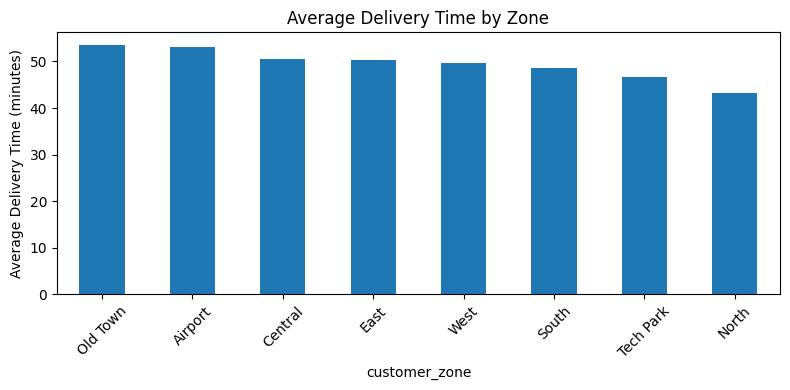

In [10]:

zone_time = df.groupby("customer_zone")["delivery_duration_min"].mean().sort_values(ascending=False)

print(zone_time.round(2))
zone_time.plot(kind="bar", figsize=(8, 4), ylabel="Average Delivery Time (minutes)",
               title="Average Delivery Time by Zone")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


traffic_level
Low       41.98
Medium    46.51
High      54.12
Severe    61.20
Name: delivery_duration_min, dtype: float64


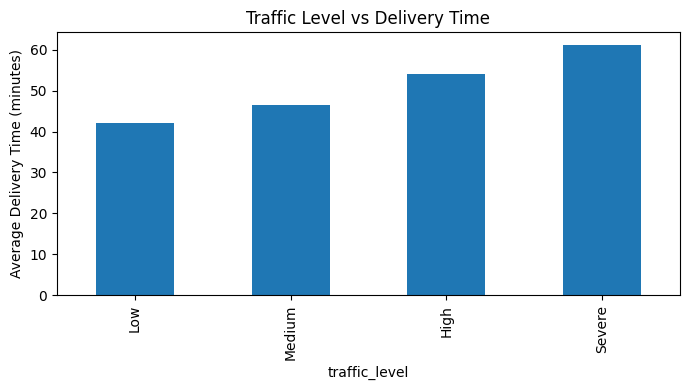

In [11]:

traffic_time = df.groupby("traffic_level")["delivery_duration_min"].mean().reindex(
    ["Low", "Medium", "High", "Severe"]
)

print(traffic_time.round(2))
traffic_time.plot(kind="bar", figsize=(7, 4), ylabel="Average Delivery Time (minutes)",
                  title="Traffic Level vs Delivery Time")
plt.tight_layout()
plt.show()


rain_level
None          NaN
Light       49.85
Moderate    52.15
Heavy       54.21
Name: delivery_duration_min, dtype: float64


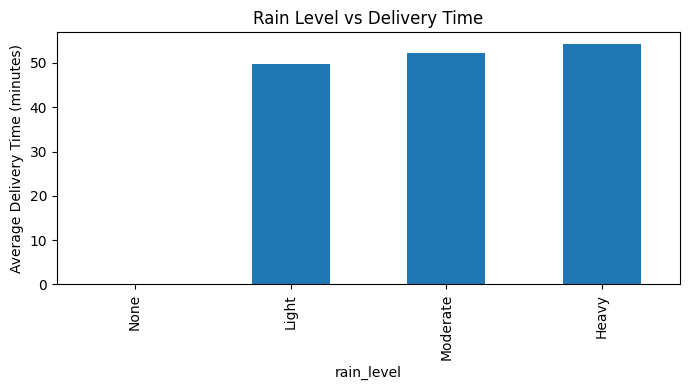

In [12]:

rain_time = df.groupby("rain_level")["delivery_duration_min"].mean().reindex(
    ["None", "Light", "Moderate", "Heavy"]
)

print(rain_time.round(2))
rain_time.plot(kind="bar", figsize=(7, 4), ylabel="Average Delivery Time (minutes)",
               title="Rain Level vs Delivery Time")
plt.tight_layout()
plt.show()


restaurant
Tandoori Trail       21.59
Curry Corner         18.55
Pizza Point          17.29
South Street Cafe    16.44
Spice Hub            15.74
Noodle Nest          15.33
Green Bowl           13.93
Urban Bites          13.45
Wrap Works           13.40
Burger Barn          12.14
Name: pickup_wait_min, dtype: float64


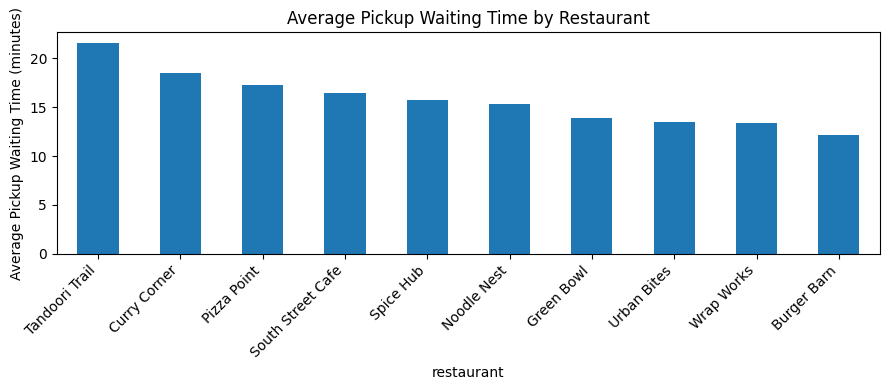

In [13]:

restaurant_time = df.groupby("restaurant")["pickup_wait_min"].mean().sort_values(ascending=False)

print(restaurant_time.round(2))
restaurant_time.plot(kind="bar", figsize=(9, 4), ylabel="Average Pickup Waiting Time (minutes)",
                     title="Average Pickup Waiting Time by Restaurant")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


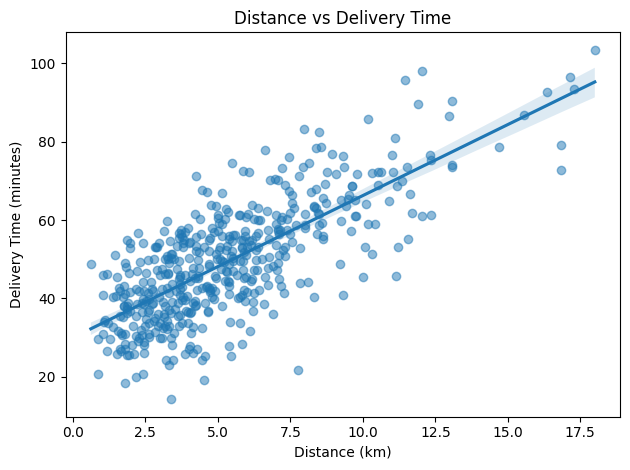

Distance-duration correlation: 0.744


In [14]:

sns.regplot(
    data=df, x="distance_km", y="delivery_duration_min",
    scatter_kws={"alpha": 0.5}
)
plt.title("Distance vs Delivery Time")
plt.xlabel("Distance (km)")
plt.ylabel("Delivery Time (minutes)")
plt.tight_layout()
plt.show()

print("Distance-duration correlation:",
      round(df["distance_km"].corr(df["delivery_duration_min"]), 3))


order_hour
0.0     51.40
1.0     48.84
2.0     43.64
3.0     52.26
4.0     51.61
5.0     49.65
6.0     54.88
7.0     49.86
8.0     46.50
9.0     47.39
10.0    48.23
11.0    50.56
12.0    50.48
13.0    49.47
14.0    47.65
15.0    50.13
16.0    49.91
17.0    56.19
18.0    42.21
19.0    50.65
20.0    47.64
21.0    49.56
22.0    52.40
23.0    41.86
Name: delivery_duration_min, dtype: float64


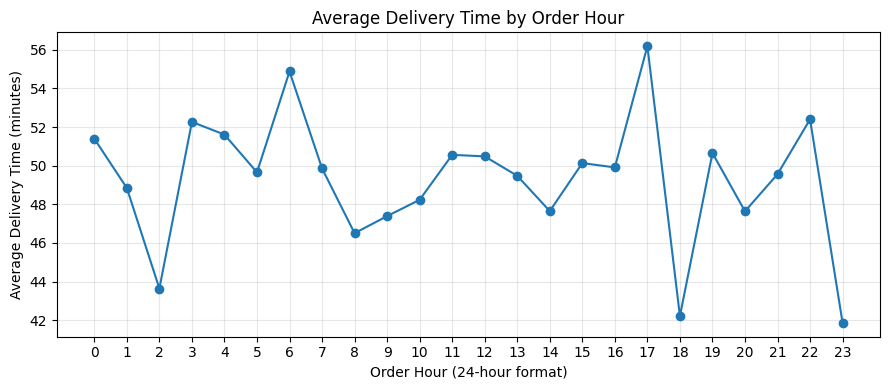

In [15]:

hourly_time = df.groupby("order_hour")["delivery_duration_min"].mean()

print(hourly_time.round(2))
hourly_time.plot(kind="line", marker="o", figsize=(9, 4))
plt.title("Average Delivery Time by Order Hour")
plt.xlabel("Order Hour (24-hour format)")
plt.ylabel("Average Delivery Time (minutes)")
plt.xticks(range(0, 24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [16]:

numeric_features = [
    "delivery_duration_min",
    "pickup_wait_min",
    "distance_km",
    "temperature_c",
    "visibility_km",
    "experience_months",
    "order_value"
]

correlations = df[numeric_features].corr()["delivery_duration_min"].drop(
    "delivery_duration_min"
).sort_values(key=abs, ascending=False)

print("Correlation with delivery duration:")
display(correlations.to_frame("correlation"))


Correlation with delivery duration:


,correlation
distance_km,0.744471
pickup_wait_min,0.349605
visibility_km,-0.049079
experience_months,-0.014314
order_value,-0.012601
temperature_c,-0.000886
